In [66]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from matplotlib.colors import LogNorm
import cartopy.crs as ccrs
import cartopy.feature as cfeature

In [67]:
# Cleaned, RONI-tagged Kuroshio observations (01_data_prep_roni_gdp)
df = pd.read_parquet("../data/kuroshio_obs_clean.parquet")

# Velocity analysis uses drogued drifters only (flag cross-checked against drogue loss date)
df_drogued = df[df["drogued"]].copy()

print(len(df), "obs total |", len(df_drogued), "drogued")

4623446 obs total | 2136984 drogued


### Sampling by ENSO phase

In [68]:
# --- How much data each ENSO phase has ---
def phase_summary(d, value_col):
    s = d.groupby("enso").agg(n_obs=(value_col, "count"),     # non-missing values
                              n_drifters=("id", "nunique"))   # distinct drifters
    s["share_obs"] = (s["n_obs"] / s["n_obs"].sum()).round(3)
    return s

print("Velocity (drogued):\n", phase_summary(df_drogued, "ve"), "\n")
print("SST (all drifters):\n", phase_summary(df, "sst"))

Velocity (drogued):
            n_obs  n_drifters  share_obs
enso                                   
El Niño   252229         212      0.118
La Niña   836997         502      0.392
Neutral  1047758         744      0.490 

SST (all drifters):
            n_obs  n_drifters  share_obs
enso                                   
El Niño   725198         381      0.165
La Niña  1677973         778      0.382
Neutral  1991911        1038      0.453


### Spatial support per 1 degree cell

In [69]:
# --- Grid definition (region bounds kept as variables so any box works) ---
LON_MIN, LON_MAX = 115, 145
LAT_MIN, LAT_MAX = 15, 40
RES = 1.0                                              # cell size in degrees

lon_edges = np.arange(LON_MIN, LON_MAX + RES, RES)     # cell boundaries
lat_edges = np.arange(LAT_MIN, LAT_MAX + RES, RES)
nx, ny = len(lon_edges) - 1, len(lat_edges) - 1        # number of cells each way

def cell_support(d, value_col):
    """Return 2-D arrays (lat x lon) of observation counts and distinct-drifter counts."""
    d = d[d[value_col].notna()]                        # only rows with a valid value
    # Which cell each observation falls in (clip keeps points on the far edge in the last cell)
    ix = np.clip(((d["lon"].values - LON_MIN) // RES).astype(int), 0, nx - 1)
    iy = np.clip(((d["lat"].values - LAT_MIN) // RES).astype(int), 0, ny - 1)
    g = (pd.DataFrame({"iy": iy, "ix": ix, "id": d["id"].values})
           .groupby(["iy", "ix"])
           .agg(n_obs=("id", "size"), n_drifters=("id", "nunique")))
    # Fill empty grids, then drop the counts into their cells
    n_obs = np.zeros((ny, nx)); n_dr = np.zeros((ny, nx))
    iy_idx, ix_idx = g.index.get_level_values("iy"), g.index.get_level_values("ix")
    n_obs[iy_idx, ix_idx] = g["n_obs"].values
    n_dr[iy_idx, ix_idx] = g["n_drifters"].values
    return n_obs, n_dr

In [70]:
phases = ["All", "Neutral", "La Niña", "El Niño"]
support_vel = {}
for p in phases:
    sub = df_drogued if p == "All" else df_drogued[df_drogued["enso"] == p]
    support_vel[p] = cell_support(sub, "ve")           # (n_obs, n_drifters)

### Effect of the drogue policy on velocity coverage

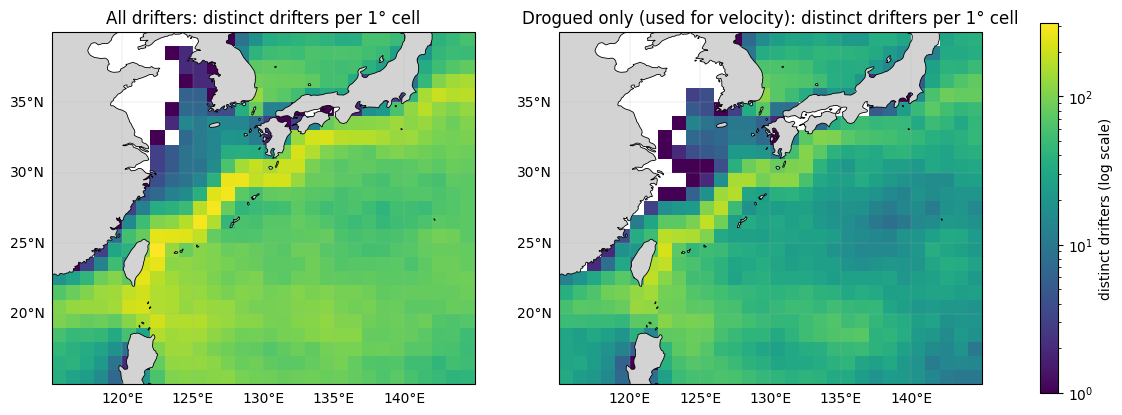

In [71]:
# Velocity support before and after the drogue rule (shared log colour scale)
fig, axes = plt.subplots(1, 2, figsize=(15, 6), subplot_kw={"projection": proj})
norm = LogNorm(vmin=1, vmax=ndr_all.max())

for ax, n_dr, title in [(axes[0], ndr_all, "All drifters"),
                        (axes[1], ndr_dro, "Drogued only (used for velocity)")]:
    im = ax.pcolormesh(lon_edges, lat_edges, np.where(n_dr > 0, n_dr, np.nan),
                       norm=norm, cmap="viridis", transform=proj)
    ax.add_feature(cfeature.LAND, facecolor="lightgrey", zorder=2)
    ax.coastlines(resolution="50m", linewidth=0.6, zorder=3)
    ax.set_extent([LON_MIN, LON_MAX, LAT_MIN, LAT_MAX], crs=proj)
    gl = ax.gridlines(draw_labels=True, linewidth=0.3, alpha=0.5)
    gl.top_labels = gl.right_labels = False
    ax.set_title(f"{title}: distinct drifters per {RES:g}° cell")

fig.colorbar(im, ax=axes, label="distinct drifters (log scale)", shrink=0.8)
plt.show()

                hours median drifters/cell cells ≥5 drifters  \
all drifters  4623446                 74.0               93%   
drogued only  2136984                 30.0               90%   

             cells ≥10 drifters cells ≥20 drifters  
all drifters                90%                85%  
drogued only                86%                72%  


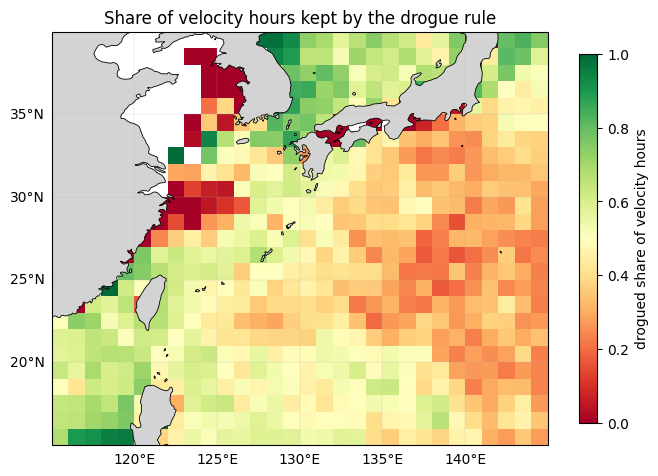

In [72]:
# Velocity support with all drifters vs drogued only
nobs_all, ndr_all = cell_support(df, "ve")          # every drifter, any drogue state
nobs_dro, ndr_dro = support_vel["All"]              # drogued only (computed above)
ocean = ndr_all > 0                                 # cells with any velocity data

policy = pd.DataFrame({
    "all drifters": {"hours": int(nobs_all.sum()),
                     "median drifters/cell": np.median(ndr_all[ocean]),
                     "cells ≥5 drifters":  f"{(ndr_all[ocean] >= 5).mean():.0%}",
                     "cells ≥10 drifters": f"{(ndr_all[ocean] >= 10).mean():.0%}",
                     "cells ≥20 drifters": f"{(ndr_all[ocean] >= 20).mean():.0%}"},
    "drogued only": {"hours": int(nobs_dro.sum()),
                     "median drifters/cell": np.median(ndr_dro[ocean]),
                     "cells ≥5 drifters":  f"{(ndr_dro[ocean] >= 5).mean():.0%}",
                     "cells ≥10 drifters": f"{(ndr_dro[ocean] >= 10).mean():.0%}",
                     "cells ≥20 drifters": f"{(ndr_dro[ocean] >= 20).mean():.0%}"},
}).T
print(policy)

# Where is coverage lost? Share of each cell's velocity hours kept by the rule
kept = np.where(ocean, nobs_dro / np.where(ocean, nobs_all, 1), np.nan)

fig, ax = plt.subplots(figsize=(8, 6), subplot_kw={"projection": proj})
im = ax.pcolormesh(lon_edges, lat_edges, kept, cmap="RdYlGn", vmin=0, vmax=1, transform=proj)
fig.colorbar(im, ax=ax, label="drogued share of velocity hours", shrink=0.8)
ax.add_feature(cfeature.LAND, facecolor="lightgrey", zorder=2)
ax.coastlines(resolution="50m", linewidth=0.6, zorder=3)
ax.set_extent([LON_MIN, LON_MAX, LAT_MIN, LAT_MAX], crs=proj)
gl = ax.gridlines(draw_labels=True, linewidth=0.3, alpha=0.5)
gl.top_labels = gl.right_labels = False
ax.set_title("Share of velocity hours kept by the drogue rule")
plt.show()

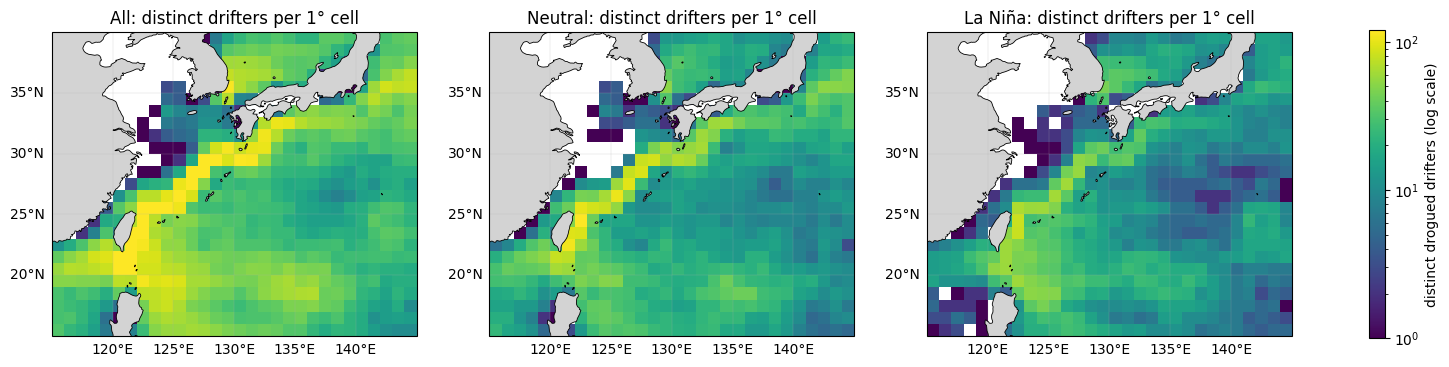

In [73]:
proj = ccrs.PlateCarree()                       # plain lon/lat projection
fig, axes = plt.subplots(1, 3, figsize=(20, 5),
                         subplot_kw={"projection": proj})
norm = LogNorm(vmin=1, vmax=support_vel["Neutral"][1].max())

for ax, p in zip(axes, phases):
    n_dr = support_vel[p][1]
    im = ax.pcolormesh(lon_edges, lat_edges,
                       np.where(n_dr > 0, n_dr, np.nan),
                       norm=norm, cmap="viridis", transform=proj)
    ax.add_feature(cfeature.LAND, facecolor="lightgrey", zorder=2)   # grey land on top
    ax.coastlines(resolution="50m", linewidth=0.6, zorder=3)          # coastline outline
    ax.set_extent([LON_MIN, LON_MAX, LAT_MIN, LAT_MAX], crs=proj)
    gl = ax.gridlines(draw_labels=True, linewidth=0.3, alpha=0.5)
    gl.top_labels = gl.right_labels = False
    ax.set_title(f"{p}: distinct drifters per {RES:g}° cell")

fig.colorbar(im, ax=axes, label="distinct drogued drifters (log scale)", shrink=0.8)
plt.show()

In [74]:
ocean = support_vel["All"][1] > 0                      # cells with any data at all

rows = []
for p in phases:
    n_dr = support_vel[p][1]
    rows.append({
        "phase": p,
        "median drifters/cell": np.median(n_dr[ocean]),
        "cells ≥5 drifters":  f"{(n_dr[ocean] >= 5).mean():.0%}",
        "cells ≥10 drifters": f"{(n_dr[ocean] >= 10).mean():.0%}",
        "cells ≥20 drifters": f"{(n_dr[ocean] >= 20).mean():.0%}",
    })
print(pd.DataFrame(rows).set_index("phase"))

         median drifters/cell cells ≥5 drifters cells ≥10 drifters  \
phase                                                                
All                      31.0               94%                90%   
Neutral                  16.0               91%                78%   
La Niña                  11.0               81%                58%   
El Niño                   4.0               43%                 9%   

        cells ≥20 drifters  
phase                       
All                    75%  
Neutral                40%  
La Niña                24%  
El Niño                 0%  


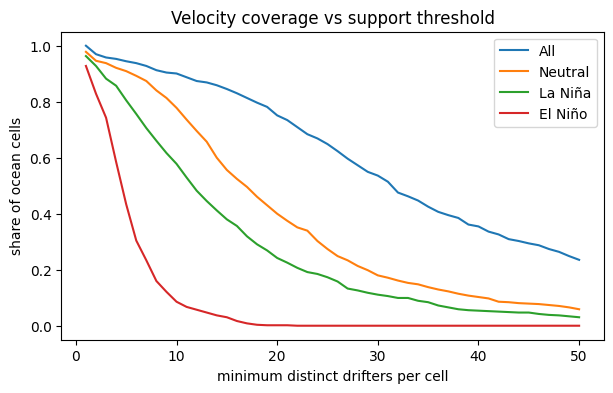

In [75]:
k = np.arange(1, 51)
fig, ax = plt.subplots(figsize=(7, 4))
for p in phases:
    n_dr = support_vel[p][1][ocean]
    ax.plot(k, [(n_dr >= i).mean() for i in k], label=p)
ax.set(xlabel="minimum distinct drifters per cell", ylabel="share of ocean cells",
       title="Velocity coverage vs support threshold")
ax.legend(); plt.show()

### Temporal Coverage

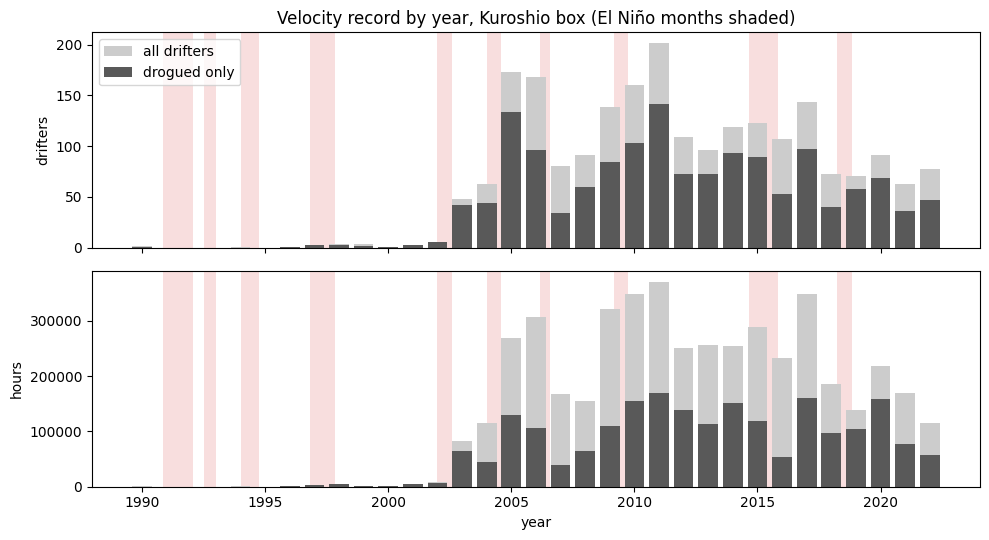

median year of drogued hours: 2013


In [76]:
# Velocity record of the whole box by year: all drifters vs drogued only
year_dro = df_drogued["time"].dt.year
year_all = df["time"].dt.year

history = pd.DataFrame({
    "drifters": df_drogued.groupby(year_dro)["id"].nunique(),
    "hours":    df_drogued.groupby(year_dro).size(),
})
history_all = pd.DataFrame({
    "drifters": df.groupby(year_all)["id"].nunique(),
    "hours":    df.groupby(year_all).size(),
})

# El Niño months from the RONI calendar (not from drifter rows)
roni_phase = pd.read_csv("../data/roni_phase.csv", index_col=0, parse_dates=True)["enso"]
el_nino_months = roni_phase["1990":"2022"][lambda s: s == "El Niño"].index.to_period("M")

fig, axes = plt.subplots(2, 1, figsize=(10, 5.5), sharex=True)
for ax, col in zip(axes, history.columns):
    for m in el_nino_months:
        x0 = m.year + (m.month - 1) / 12 - 0.5          # -0.5 aligns with bars centred on each year
        ax.axvspan(x0, x0 + 1 / 12, color="tab:red", alpha=0.15, lw=0)
    ax.bar(history_all.index, history_all[col], color="0.8", label="all drifters")   # light, behind
    ax.bar(history.index, history[col], color="0.35", label="drogued only")         # dark, in front
    ax.set_ylabel(col)
axes[0].legend(loc="upper left")
axes[0].set_title("Velocity record by year, Kuroshio box (El Niño months shaded)")
axes[-1].set_xlabel("year")
plt.tight_layout(); plt.show()

print(f"median year of drogued hours: {year_dro.median():.0f}")

Distinct drifters (top) and hours (bottom) per year in the Kuroshio box, for all drifters (light) and drogued drifters used for velocity (dark). El Niño months are shaded (RONI ≥ +0.5 °C for ≥5 consecutive overlapping seasons). The box was barely sampled before 2002, so the 1990s El Niño events, including 1997–98, contribute almost no data, and El Niño velocity estimates rest on six events between 2002 and 2019. The drogue criterion removes proportionally more hours than drifters, because drifters typically stay long after losing their drogues. Hour counts are therefore a poor guide to support.

### Aggregation

Aggregate to one row per drifter per cell. Hourly observations from one drifter are strongly correlated, so later uncertainty steps resample drifters, not hours. Sums are stored so any set of drifters recombines into an exact mean.

In [77]:
def aggregate_by_drifter(d, value_cols):
    """One row per (cell, drifter, ENSO phase): hour count and sum of each variable.
    The drifter is the independent unit, so later steps resample these rows."""
    d = d.dropna(subset=value_cols)                       # only rows with valid values
    # Same cell assignment as cell_support, so cells line up with the support maps
    ix = np.clip(((d["lon"].values - LON_MIN) // RES).astype(int), 0, nx - 1)
    iy = np.clip(((d["lat"].values - LAT_MIN) // RES).astype(int), 0, ny - 1)
    tmp = pd.DataFrame({"iy": iy, "ix": ix, "id": d["id"].values, "enso": d["enso"].values})
    for c in value_cols:
        tmp[c] = d[c].values
    return (tmp.groupby(["iy", "ix", "id", "enso"])
               .agg(n=(value_cols[0], "size"),                        # hours in this cell
                    **{f"sum_{c}": (c, "sum") for c in value_cols})   # sum of each variable
               .reset_index())


agg_vel = aggregate_by_drifter(df_drogued, ["ve", "vn"])   # velocity: drogued only
agg_sst = aggregate_by_drifter(df, ["sst"])                # SST: all drifters

print(f"velocity: {len(agg_vel):,} rows | sst: {len(agg_sst):,} rows")

velocity: 23,722 rows | sst: 48,153 rows


In [78]:
agg_vel.to_parquet("../data/agg_vel_1deg.parquet")
agg_sst.to_parquet("../data/agg_sst_1deg.parquet")

In [79]:
print(agg_vel)
print(agg_sst)

       iy  ix               id     enso    n     sum_ve     sum_vn
0       0   0            49632  Neutral   70  -1.539700   1.969500
1       0   0           139801  El Niño  119  29.830900  -6.839100
2       0   0           139804  El Niño  147  29.963699  12.354700
3       0   0  300234060291780  Neutral   74  14.902200  30.791599
4       0   0  300234060999470  Neutral   76  -6.300600  32.247200
...    ..  ..              ...      ...  ...        ...        ...
23717  24  29  300234065708610  Neutral   49  23.745600  -5.356500
23718  24  29  300234066335930  Neutral    8  -3.767316   2.981386
23719  24  29  300234066431370  Neutral   91  -7.275721  30.663370
23720  24  29  300234067542090  La Niña  114   6.449013 -40.337212
23721  24  29  300534061384140  La Niña   21   6.551003   0.209187

[23722 rows x 7 columns]
       iy  ix               id     enso    n       sum_sst
0       0   0            49632  Neutral   70  21162.810547
1       0   0            55356  Neutral  318  95146.

In [80]:
# Check: how unevenly do drifters contribute to each cell?
hours = agg_vel.groupby(["iy", "ix", "id"])["n"].sum()     # total hours per (cell, drifter)
by_cell = hours.groupby(level=["iy", "ix"])

cell_stats = pd.DataFrame({
    "n_drifters":      by_cell.size(),                                          # actual drifters
    "n_eff_drifters":           by_cell.sum() ** 2 / by_cell.apply(lambda s: (s ** 2).sum()),  # effective drifters
    "top_share":       by_cell.max() / by_cell.sum(),                           # share from biggest contributor
    "hours_per_visit": by_cell.median(),                                        # typical hours per drifter
})
cell_stats["eff_ratio"] = cell_stats["n_eff_drifters"] / cell_stats["n_drifters"]

print(cell_stats.median().round(2).to_string())

n_drifters         31.00
n_eff_drifters     16.20
top_share           0.13
hours_per_visit    75.00
eff_ratio           0.55


Drifter contributions within cells are uneven. A typical drifter remains in a 1° cell for about 75 hours, so its hourly records are strongly correlated. In the median cell, the largest single contributor supplies 13% of the hours, and the 31 drifters present are equivalent to about 16 equally contributing drifters (55%). Hourly observation counts therefore greatly overstate the independent information in each cell, which motivates estimating uncertainty by resampling whole drifters rather than individual observations.

### CLIMATOLOGY

In [81]:
# Cell centres (for arrows)
lon_c = (lon_edges[:-1] + lon_edges[1:]) / 2
lat_c = (lat_edges[:-1] + lat_edges[1:]) / 2

def cell_means(agg, value_cols):
    """
    Per-cell mean of each variable = total sum / total hours.
    This weights every hourly observation equally (our stated definition).
    Returns 2-D arrays (lat x lon); NaN where a cell has no data.
    """
    g = agg.groupby(["iy", "ix"]).agg(
        n_obs=("n", "sum"),                                        # total hours in the cell
        n_drifters=("id", "nunique"),                              # distinct drifters
        **{f"sum_{c}": (f"sum_{c}", "sum") for c in value_cols})   # summed values
    iy, ix = g.index.get_level_values("iy"), g.index.get_level_values("ix")

    out = {"n_obs": np.zeros((ny, nx)), "n_drifters": np.zeros((ny, nx))}
    out["n_obs"][iy, ix] = g["n_obs"].values
    out["n_drifters"][iy, ix] = g["n_drifters"].values
    for c in value_cols:
        out[f"mean_{c}"] = np.full((ny, nx), np.nan)
        out[f"mean_{c}"][iy, ix] = (g[f"sum_{c}"] / g["n_obs"]).values
    return out


vel = cell_means(agg_vel, ["ve", "vn"])
sst = cell_means(agg_sst, ["sst"])

# Magnitude of the MEAN VELOCITY VECTOR (not the average of hourly speeds)
vel["mean_speed"] = np.hypot(vel["mean_ve"], vel["mean_vn"])

print(f"max mean speed: {np.nanmax(vel['mean_speed']):.2f} m/s")
print(f"SST range: {np.nanmin(sst['mean_sst'])-273.15:.1f} to {np.nanmax(sst['mean_sst'])-273.15:.1f} °C")

max mean speed: 1.11 m/s
SST range: 11.3 to 29.9 °C


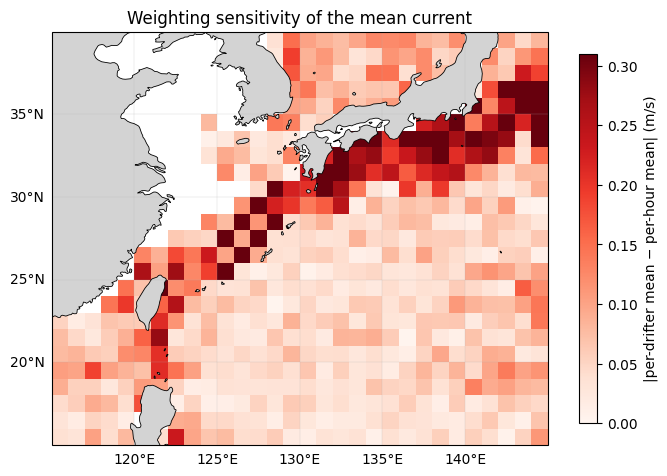

median difference: 0.060 m/s | 90th pct: 0.225 m/s | cells > 0.10 m/s: 28%


In [82]:
# --- Weighting sensitivity: equal weight per hour vs equal weight per drifter ---
# Each drifter's own mean in each cell (summing its rows across ENSO phases first)
per_dr = agg_vel.groupby(["iy", "ix", "id"])[["n", "sum_ve", "sum_vn"]].sum()
per_dr["ve"] = per_dr["sum_ve"] / per_dr["n"]
per_dr["vn"] = per_dr["sum_vn"] / per_dr["n"]

# Equal weight per drifter = plain average of the drifter means
dr_mean = per_dr.groupby(level=["iy", "ix"])[["ve", "vn"]].mean()
ve_dr = np.full((ny, nx), np.nan); vn_dr = np.full((ny, nx), np.nan)
iy, ix = dr_mean.index.get_level_values("iy"), dr_mean.index.get_level_values("ix")
ve_dr[iy, ix] = dr_mean["ve"].values
vn_dr[iy, ix] = dr_mean["vn"].values

# Size of the difference between the two mean vectors (m/s)
diff = np.hypot(ve_dr - vel["mean_ve"], vn_dr - vel["mean_vn"])
diff = np.where(show_vel, diff, np.nan)                    # same display mask as the climatology

fig, ax = plt.subplots(figsize=(8, 6), subplot_kw={"projection": proj})
im = ax.pcolormesh(lon_edges, lat_edges, diff, cmap="Reds", vmin=0,
                   vmax=np.nanpercentile(diff, 95), transform=proj)
fig.colorbar(im, ax=ax, label="|per-drifter mean − per-hour mean| (m/s)", shrink=0.8)
ax.add_feature(cfeature.LAND, facecolor="lightgrey", zorder=2)
ax.coastlines(resolution="50m", linewidth=0.6, zorder=3)
ax.set_extent([LON_MIN, LON_MAX, LAT_MIN, LAT_MAX], crs=proj)
gl = ax.gridlines(draw_labels=True, linewidth=0.3, alpha=0.5)
gl.top_labels = gl.right_labels = False
ax.set_title("Weighting sensitivity of the mean current")
plt.show()

print(f"median difference: {np.nanmedian(diff):.3f} m/s | "
      f"90th pct: {np.nanpercentile(diff, 90):.3f} m/s | "
      f"cells > 0.10 m/s: {(diff > 0.10)[show_vel].mean():.0%}")

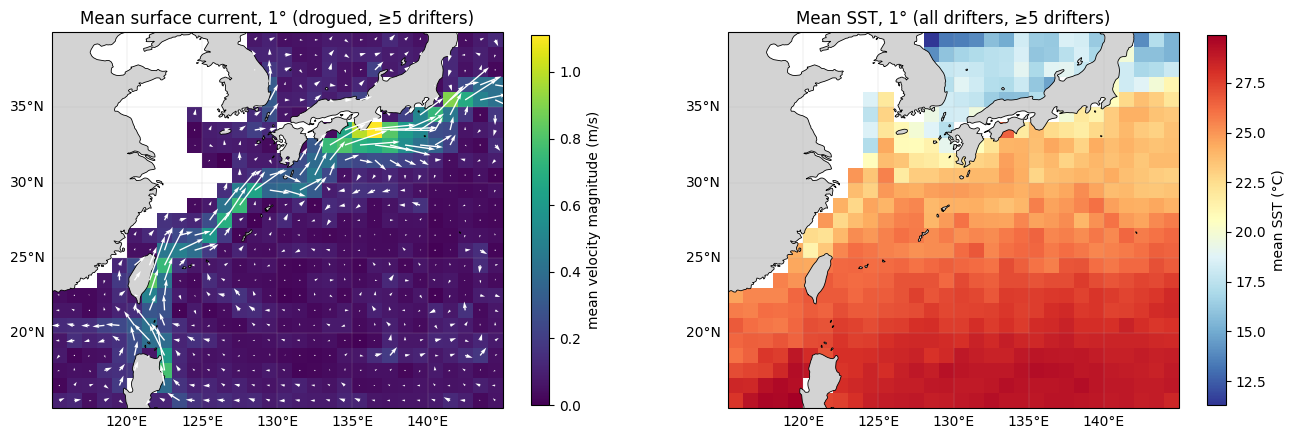

In [83]:
# Provisional display mask until the reliability rule (Step 5) is defined
MIN_DRIFTERS = 5
show_vel = vel["n_drifters"] >= MIN_DRIFTERS
show_sst = sst["n_drifters"] >= MIN_DRIFTERS

proj = ccrs.PlateCarree()
fig, axes = plt.subplots(1, 2, figsize=(16, 6), subplot_kw={"projection": proj})

# --- Left: mean current (colour = magnitude, arrows = direction) ---
ax = axes[0]
im = ax.pcolormesh(lon_edges, lat_edges, np.where(show_vel, vel["mean_speed"], np.nan),
                   cmap="viridis", vmin=0, transform=proj)
ax.quiver(lon_c, lat_c,
          np.where(show_vel, vel["mean_ve"], np.nan),
          np.where(show_vel, vel["mean_vn"], np.nan),
          scale=8, width=0.003, color="white", transform=proj, zorder=4)
fig.colorbar(im, ax=ax, label="mean velocity magnitude (m/s)", shrink=0.8)
ax.set_title(f"Mean surface current, {RES:g}° (drogued, ≥{MIN_DRIFTERS} drifters)")

# --- Right: mean SST in °C ---
ax = axes[1]
im = ax.pcolormesh(lon_edges, lat_edges, np.where(show_sst, sst["mean_sst"] - 273.15, np.nan),
                   cmap="RdYlBu_r", transform=proj)
fig.colorbar(im, ax=ax, label="mean SST (°C)", shrink=0.8)
ax.set_title(f"Mean SST, {RES:g}° (all drifters, ≥{MIN_DRIFTERS} drifters)")

# --- Shared map styling ---
for ax in axes:
    ax.add_feature(cfeature.LAND, facecolor="lightgrey", zorder=2)
    ax.coastlines(resolution="50m", linewidth=0.6, zorder=3)
    ax.set_extent([LON_MIN, LON_MAX, LAT_MIN, LAT_MAX], crs=proj)
    gl = ax.gridlines(draw_labels=True, linewidth=0.3, alpha=0.5)
    gl.top_labels = gl.right_labels = False
plt.show()